# SupportBot — Modèle encodeur–décodeur

Ce notebook construit et entraîne le chatbot de service client. Il part des **paires nettoyées**
produites par le notebook `01_donnees.ipynb` (fichier `data/processed/paires_nettoyees.csv`) :
chaque paire associe le **message d'un client** (l'entrée du modèle) à la **réponse d'un agent**
(la sortie que le modèle apprend à générer).

**Étapes du notebook :**

1. Découpage des paires en ensembles d'**entraînement**, de **validation** et de **test** ;
2. Construction du **vocabulaire** (avec les tokens spéciaux `<PAD>`, `<UNK>`, `<SOS>`, `<EOS>` et `<SEP>`) ;
3. **Représentation numérique** des textes (chaque token devient un numéro) ;
4. **Modèle 1** : encodeur–décodeur LSTM sans attention (modèle de référence) ;
5. **Modèle 2** : ajout du mécanisme d'**attention** ;
6. **Modèle 3** : ajout d'une **recherche TF-IDF** (RAG inspiré du raisonnement à partir de cas : CBR) :
   le modèle reçoit, en plus du message, la réponse d'un cas similaire ;
7. **Génération** de réponses (greedy et beam search) ;
8. **Évaluation** et comparaison des trois modèles.

**Deux exécutions, sur le même ordinateur :**

|                      | Mode test                                              | Mode réel                     |
|----------------------|--------------------------------------------------------|-------------------------------|
| Paires utilisées     | 5 000                                                  | 150 000                       |
| Objectif             | Vérifier rapidement que le code fonctionne de bout en bout | Entraîner les modèles finaux |
| Résultats présentés  | Non                                                    | Oui                           |

**Entraînement sur processeur (CPU).** L'ordinateur utilisé (Intel Core i7-1260P, 12 cœurs,
16 Go de mémoire) n'a pas de carte graphique NVIDIA : PyTorch effectue donc tous les calculs sur
le processeur. Pour que l'entraînement reste réalisable en quelques heures, le modèle est
volontairement **de taille modeste** (vocabulaire de 8 000 tokens, petites couches LSTM), et le
modèle est **sauvegardé à chaque epoch** pour pouvoir reprendre en cas d'interruption.

**Pourquoi 150 000 paires, et pas les 681 961 ?**

- **Le temps** : sur CPU, entraîner sur toutes les paires prendrait environ 4 à 5 fois plus
  longtemps, pour chacun des trois modèles, ce qui dépasserait les délais du projet ;
- **La quantité suffit** : 150 000 paires représentent déjà un volume important pour un modèle
  LSTM, et le dataset doit rester entraînable avec les ressources disponibles ;
- **La représentativité** : l'échantillon est tiré au hasard parmi toutes les paires ; il conserve
  donc la diversité des marques et des types de demandes.

Le passage d'un mode à l'autre se fait en changeant une seule variable (`MODE_TEST`) dans la
cellule de configuration. **Les résultats présentés dans ce notebook sont ceux du mode réel.**

## 1. Configuration

On fixe la **graine aléatoire** pour que les résultats soient reproductibles, on détecte l'appareil
disponible (ici le processeur) et on demande à PyTorch d'utiliser **tous les cœurs** du processeur
pour accélérer les calculs. On fixe enfin le nombre de paires utilisées pour l'entraînement.

In [4]:
import os
import random
import numpy as np
import pandas as pd
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(os.cpu_count())          # utiliser tous les cœurs du processeur
print(f"PyTorch {torch.__version__} | appareil utilisé : {device} | threads du CPU : {torch.get_num_threads()}")

N_PAIRES = 5_000                               # 5 000 pour tester le code, 150 000 pour l'entraînement final
print(f"Paires utilisées : {N_PAIRES:,}")

PyTorch 2.14.1+cpu | appareil utilisé : cpu | threads du CPU : 16
Paires utilisées : 5,000


**Interprétation :**

Aucune carte graphique NVIDIA n'est détectée : les calculs sont effectués sur le processeur (CPU),
en utilisant ses 16 threads. Le modèle est entraîné sur 150 000 paires tirées au hasard parmi les
681 961 paires nettoyées.

## 2. Chargement et échantillonnage

On charge les paires nettoyées, puis on tire un **échantillon aléatoire** : les 681 961 paires
disponibles dépassent largement ce qu'il est possible d'entraîner dans un temps raisonnable.

In [5]:
CHEMIN_PAIRES = "../data/processed/paires_nettoyees.csv"

toutes_les_paires = pd.read_csv(CHEMIN_PAIRES, keep_default_na=False)
print(f"Paires disponibles : {len(toutes_les_paires):,}")

paires = toutes_les_paires.sample(n=N_PAIRES, random_state=SEED).reset_index(drop=True)
del toutes_les_paires                          # on libère la mémoire : seul l'échantillon est utile
print(f"Échantillon        : {len(paires):,} paires")
paires.head(3)

Paires disponibles : 681,961
Échantillon        : 5,000 paires


,client_id,reponse_id,marque,message,reponse
0,2539096,2539094,sainsburys,go to to double up points for some christmas l...,"hi jordan , really sorry about that . which st..."
1,1159517,1159519,Delta,exit door release a little loose ? let's put a...,"josh , certainly understand the concern but be..."
2,2696076,2696075,AppleSupport,is anyone else's iphone doing that dumb shit w...,we'd like to help . dm us the ios version you'...


**Interprétation :**

Les 681 961 paires nettoyées sont chargées, puis un échantillon aléatoire de 150 000 paires est
tiré (graine 42, donc le même échantillon à chaque exécution). Les premières lignes montrent des
paires de marques différentes, signe que le tirage aléatoire mélange bien les données. Le tableau
complet est ensuite supprimé de la mémoire, puisque seul l'échantillon est utilisé dans la suite
du notebook.

## 3. Découpage train / validation / test

On divise l'échantillon en trois ensembles :
- **entraînement (80 %)** : le modèle apprend sur ces paires ;
- **validation (10 %)** : on surveille l'apprentissage (surapprentissage) et on choisit le
  meilleur modèle ;
- **test (10 %)** : on évalue le modèle final, sur des paires qu'il n'a **jamais vues**.

L'échantillon ayant déjà été mélangé au hasard, il suffit de le découper dans l'ordre.

In [6]:
n_train = int(0.8 * len(paires))
n_val = int(0.1 * len(paires))

train = paires.iloc[:n_train].reset_index(drop=True)
val = paires.iloc[n_train:n_train + n_val].reset_index(drop=True)
test = paires.iloc[n_train + n_val:].reset_index(drop=True)

decoupage = pd.DataFrame({
    "Ensemble": ["Entraînement (train)", "Validation", "Test"],
    "Paires": [len(train), len(val), len(test)],
})
decoupage["% des paires"] = (decoupage["Paires"] / len(paires) * 100).round(1)
decoupage

,Ensemble,Paires,% des paires
0,Entraînement (train),4000,80.0
1,Validation,500,10.0
2,Test,500,10.0


**Interprétation :**

L'échantillon est découpé en 120 000 paires d'entraînement (80 %), 15 000 de validation (10 %)
et 15 000 de test (10 %). Les trois ensembles ne se chevauchent pas : les paires de test ne sont
jamais vues pendant l'entraînement, ce qui permet une évaluation honnête du modèle final.

## 4. Vocabulaire

Le modèle ne lit pas des mots mais des **numéros**. Le vocabulaire associe un numéro unique à
chaque token. Choix effectués :

- **Un vocabulaire commun** aux messages et aux réponses : les deux sont écrits dans la même
  langue (l'anglais du service client) et partagent la plupart de leurs mots. Ce choix est aussi
  nécessaire pour le modèle 3 (RAG), dont l'entrée contient à la fois un message et une réponse.
- **Cinq tokens spéciaux**, placés en tête du vocabulaire :

| Token | Numéro | Rôle |
|---|---|---|
| `<PAD>` | 0 | Remplissage, pour que toutes les séquences d'un paquet aient la même longueur |
| `<UNK>` | 1 | Remplace les mots absents du vocabulaire (mots inconnus) |
| `<SOS>` | 2 | Début de phrase : signal « commence à écrire » pour le décodeur |
| `<EOS>` | 3 | Fin de phrase : le décodeur s'arrête quand il le génère |
| `<SEP>` | 4 | Séparateur entre le message et la réponse du cas similaire (modèle 3, RAG) |

- **Seuls les mots fréquents** sont conservés : au maximum 8 000 tokens, apparaissant au moins
  3 fois. Les mots rares (fautes de frappe, noms propres) deviennent `<UNK>`. La taille du
  vocabulaire a un effet direct sur la vitesse : à chaque étape, le décodeur calcule une
  probabilité pour **chaque** token du vocabulaire. Une taille de 10 000 garde l'entraînement sur processeur réalisable, tout en couvrant la grande majorité des mots.
- **Le vocabulaire est construit uniquement sur l'ensemble d'entraînement.** S'il incluait la
  validation ou le test, le modèle « connaîtrait » déjà des mots qu'il n'est pas censé avoir vus,
  et son évaluation serait trop optimiste (fuite de données).

*Les tokens `<url>` et `<num>`, créés lors du nettoyage, sont des tokens ordinaires : ils sont
assez fréquents pour entrer naturellement dans le vocabulaire.*

In [7]:
from collections import Counter

TOKENS_SPECIAUX = ["<PAD>", "<UNK>", "<SOS>", "<EOS>", "<SEP>"]
PAD, UNK, SOS, EOS, SEP = range(len(TOKENS_SPECIAUX))   # PAD = 0, UNK = 1, SOS = 2, EOS = 3, SEP = 4

TAILLE_MAX_VOCAB = 8_000
FREQ_MIN = 2 if N_PAIRES < 50_000 else 3      # petit échantillon de test : on garde les mots vus 2 fois

# Compter les tokens des messages ET des réponses de l'entraînement (uniquement)
compteur = Counter()
for texte in pd.concat([train["message"], train["reponse"]]):
    compteur.update(texte.split())
print(f"Tokens différents dans l'entraînement : {len(compteur):,}")

# Garder les plus fréquents
mots_gardes = [mot for mot, n in compteur.most_common(TAILLE_MAX_VOCAB - len(TOKENS_SPECIAUX))
               if n >= FREQ_MIN]

id2mot = TOKENS_SPECIAUX + mots_gardes                  # numéro -> mot
mot2id = {mot: i for i, mot in enumerate(id2mot)}       # mot -> numéro
TAILLE_VOCAB = len(id2mot)

print(f"Taille du vocabulaire : {TAILLE_VOCAB:,} tokens")
print("Les 15 premiers :", id2mot[:15])

Tokens différents dans l'entraînement : 10,572
Taille du vocabulaire : 4,975 tokens
Les 15 premiers : ['<PAD>', '<UNK>', '<SOS>', '<EOS>', '<SEP>', '.', 'to', 'the', ',', 'you', 'and', 'a', '?', 'i', 'for']


**Interprétation :**

Les 120 000 paires d'entraînement contiennent **XX XXX tokens différents**, mais la plupart sont
très rares : beaucoup n'apparaissent qu'une ou deux fois (fautes de frappe, noms propres, mots
rares). C'est conforme à la loi de Zipf, selon laquelle quelques mots sont très fréquents et la
majorité très rares. Le vocabulaire garde donc les **8 000 tokens** les plus fréquents (dont les
5 tokens spéciaux), apparaissant au moins 3 fois. Les tokens les plus fréquents sont la
ponctuation et les mots-outils de l'anglais (« to », « the », « you »…).

In [8]:
def couverture(textes):
    """Pourcentage des tokens présents dans le vocabulaire."""
    tokens = [t for texte in textes for t in texte.split()]
    connus = sum(t in mot2id for t in tokens)
    return connus / len(tokens) * 100

resultats_vocab = pd.DataFrame({
    "Ensemble": ["Entraînement", "Validation", "Test"],
    "% de tokens connus": [round(couverture(pd.concat([d["message"], d["reponse"]])), 2)
                           for d in (train, val, test)],
})
resultats_vocab["% remplacés par <UNK>"] = (100 - resultats_vocab["% de tokens connus"]).round(2)
print(resultats_vocab)

print("\n=== Les 20 tokens les plus fréquents ===")
pd.DataFrame(compteur.most_common(20), columns=["token", "occurrences"])

       Ensemble  % de tokens connus  % remplacés par <UNK>
0  Entraînement               96.78                   3.22
1    Validation               94.70                   5.30
2          Test               94.75                   5.25

=== Les 20 tokens les plus fréquents ===


,token,occurrences
0,.,8857
1,to,5597
2,the,4395
3,",",3951
4,you,3950
5,and,2908
6,a,2855
7,?,2789
8,i,2692
9,for,2557


**Interprétation :**

Le vocabulaire couvre **XX,XX %** des tokens de l'entraînement : les tokens restants sont des mots
rares, absents du vocabulaire. Sur la validation et le test, la couverture est d'environ **XX %** :
les tokens non couverts seront remplacés par `<UNK>`, ce qui correspond à la situation réelle du
chatbot face à des messages nouveaux. La validation et le test ont une couverture presque
identique, signe que le découpage aléatoire produit des ensembles comparables. Parmi les tokens
les plus fréquents figurent la ponctuation, les mots-outils, `<url>`, ainsi que des mots typiques
du discours d'un agent (« you », « your », « we », « us », « can »).

## 5. Représentation numérique

On transforme chaque texte en une séquence de numéros de longueur fixe :

- **Message (entrée de l'encodeur)** : chaque token est remplacé par son numéro (`<UNK>` s'il est
  absent du vocabulaire), la séquence est tronquée à **43 tokens** puis complétée avec `<PAD>`.
- **Réponse (sortie du décodeur)** : on ajoute `<SOS>` au début et `<EOS>` à la fin, puis on
  tronque à **39 tokens** et on complète avec `<PAD>`, soit une longueur totale de 41.
  `<SOS>` indique au décodeur où commencer, `<EOS>` lui apprend où s'arrêter.

Les longueurs maximales (43 et 39) correspondent au 95ᵉ percentile mesuré dans le notebook
`01_donnees.ipynb`.

Exemple :
```
Message : my order is late !     →  [14, 27, 9, 85, 21, 0, 0, …]          (43 numéros)
Réponse : sorry , please dm us   →  [2, 112, 8, 40, 61, 98, 3, 0, 0, …]  (41 numéros)
                                     ↑                       ↑
                                   <SOS>                   <EOS>
```

In [9]:
MAX_LEN_MESSAGE = 43    # 95e percentile des messages (notebook 01_donnees)
MAX_LEN_REPONSE = 39    # 95e percentile des réponses (notebook 01_donnees)

def texte_vers_ids(texte):
    """Remplace chaque token par son numéro (<UNK> s'il est inconnu)."""
    return [mot2id.get(token, UNK) for token in texte.split()]

def encoder_message(texte):
    """Message -> numéros, tronqué puis complété avec <PAD> (longueur 43)."""
    ids = texte_vers_ids(texte)[:MAX_LEN_MESSAGE]
    return ids + [PAD] * (MAX_LEN_MESSAGE - len(ids))

def encoder_reponse(texte):
    """Réponse -> <SOS> + numéros + <EOS>, complétée avec <PAD> (longueur 39 + 2 = 41)."""
    ids = [SOS] + texte_vers_ids(texte)[:MAX_LEN_REPONSE] + [EOS]
    return ids + [PAD] * (MAX_LEN_REPONSE + 2 - len(ids))

def ids_vers_texte(ids):
    """Numéros -> texte (s'arrête à <EOS>, ignore <PAD> et <SOS>)."""
    mots = []
    for i in ids:
        if i == EOS:
            break
        if i in (PAD, SOS):
            continue
        mots.append(id2mot[i])
    return " ".join(mots)

exemple = train.iloc[0]
print("Message :", exemple["message"])
print("Numéros :", encoder_message(exemple["message"]))
print("Retour  :", ids_vers_texte(encoder_message(exemple["message"])))
print("\nRéponse :", exemple["reponse"])
print("Numéros :", encoder_reponse(exemple["reponse"]))
print("Retour  :", ids_vers_texte(encoder_reponse(exemple["reponse"])))

Message : go to to double up points for some christmas lights . ask staff where to go to do it . told can't today as no staff on customer service . yet 3 members of staff stood around talking . there's a reason i normally use and
Numéros : [166, 6, 6, 942, 69, 789, 14, 127, 486, 1681, 5, 478, 357, 215, 6, 166, 6, 51, 29, 5, 332, 109, 123, 63, 53, 357, 22, 113, 59, 5, 255, 160, 827, 30, 357, 3539, 423, 1548, 5, 358, 11, 424, 13]
Retour  : go to to double up points for some christmas lights . ask staff where to go to do it . told can't today as no staff on customer service . yet 3 members of staff stood around talking . there's a reason i

Réponse : hi jordan , really sorry about that . which store did you visit ? mariya
Numéros : [2, 33, 2059, 8, 162, 39, 54, 35, 5, 121, 125, 170, 9, 407, 12, 1834, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Retour  : hi jordan , really sorry about that . which store did you visit ? mariya


**Interprétation :**

Le message est converti en 43 numéros : s'il est plus court, il est complété par des `<PAD>` (0) ;
s'il est plus long, il est tronqué, et seul son début (qui décrit généralement le problème du
client) est conservé. La réponse commence par `<SOS>` (2), se termine par `<EOS>` (3) et est
complétée par des `<PAD>` jusqu'à 41 numéros. La conversion inverse redonne le texte d'origine, à
l'exception des mots rares, qui deviennent `<UNK>`.

Certaines marques signent leurs réponses avec un prénom seul, sans symbole (par exemple
« mariya » chez Sainsbury's). Le nettoyage ne peut pas distinguer ces prénoms d'un mot ordinaire :
ils constituent une limite du nettoyage.

In [10]:
from torch.utils.data import TensorDataset, DataLoader

def vers_tenseurs(df):
    """Transforme les messages et les réponses d'un ensemble en tenseurs PyTorch."""
    X = torch.tensor([encoder_message(t) for t in df["message"]], dtype=torch.long)
    Y = torch.tensor([encoder_reponse(t) for t in df["reponse"]], dtype=torch.long)
    return X, Y

X_train, Y_train = vers_tenseurs(train)
X_val, Y_val = vers_tenseurs(val)
X_test, Y_test = vers_tenseurs(test)
print(f"Entraînement : messages {tuple(X_train.shape)} | réponses {tuple(Y_train.shape)}")
print(f"Validation   : messages {tuple(X_val.shape)} | réponses {tuple(Y_val.shape)}")
print(f"Test         : messages {tuple(X_test.shape)} | réponses {tuple(Y_test.shape)}")

BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, Y_val), batch_size=BATCH_SIZE)

X_batch, Y_batch = next(iter(train_loader))
print(f"\nUn paquet : messages {tuple(X_batch.shape)} | réponses {tuple(Y_batch.shape)}")
print(f"Nombre de paquets par epoch : {len(train_loader)}")

Entraînement : messages (4000, 43) | réponses (4000, 41)
Validation   : messages (500, 43) | réponses (500, 41)
Test         : messages (500, 43) | réponses (500, 41)

Un paquet : messages (64, 43) | réponses (64, 41)
Nombre de paquets par epoch : 63


**Interprétation :**

Les paires sont converties en tenseurs : l'ensemble d'entraînement devient une matrice de
120 000 × 43 numéros pour les messages et 120 000 × 41 pour les réponses. Les données
d'entraînement sont découpées en paquets de 64 paires, mélangés à chaque epoch, soit
1 875 paquets par epoch.

## 6. Modèle 1 : encodeur–décodeur LSTM (sans attention)

Le modèle de référence est composé de deux réseaux LSTM :

- **L'encodeur** lit le message du client token par token. Chaque numéro est d'abord transformé en
  un vecteur de 128 nombres (**embedding**), puis le LSTM met à jour sa mémoire à chaque token.
  À la fin du message, sa mémoire (l'**état caché** `h` et l'**état de cellule** `c`, de taille
  256) résume tout le message.
- **Le décodeur** reçoit ce résumé comme mémoire de départ, puis génère la réponse token par
  token : à chaque étape, une couche linéaire calcule un score pour chacun des tokens du
  vocabulaire, et le token le plus probable est choisi.

Choix effectués :

| Paramètre | Valeur | Raison |
|---|---|---|
| Taille des embeddings | 128 | Suffisant pour un vocabulaire de quelques milliers de tokens |
| Taille de la mémoire LSTM | 256 | Compromis entre capacité du modèle et temps d'entraînement sur CPU |
| Nombre de couches | 1 | Modèle de référence simple |
| Dropout | 0,3 | Désactive au hasard 30 % des valeurs pendant l'entraînement, pour limiter le surapprentissage |

Les `<PAD>` ajoutés à la fin des messages ne doivent pas modifier le résumé : l'encodeur
utilise `pack_padded_sequence`, qui indique au LSTM la vraie longueur de chaque message, pour
qu'il s'arrête au dernier vrai token.

In [11]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

TAILLE_EMBEDDING = 128
TAILLE_CACHEE = 256
DROPOUT = 0.3


class Encodeur(nn.Module):
    """Lit le message et le résume dans l'état caché (h, c) du LSTM."""

    def __init__(self, taille_vocab, taille_emb, taille_cachee, dropout):
        super().__init__()
        self.embedding = nn.Embedding(taille_vocab, taille_emb, padding_idx=PAD)
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(taille_emb, taille_cachee, batch_first=True)

    def forward(self, X):
        longueurs = (X != PAD).sum(dim=1).clamp(min=1).cpu()      # vraie longueur de chaque message
        emb = self.dropout(self.embedding(X))                     # (paquet, 43) -> (paquet, 43, 128)
        emb = pack_padded_sequence(emb, longueurs, batch_first=True, enforce_sorted=False)
        sorties, (h, c) = self.lstm(emb)                          # le LSTM ignore les <PAD>
        sorties, _ = pad_packed_sequence(sorties, batch_first=True, total_length=X.size(1))
        return sorties, (h, c)                                    # sorties : utiles pour l'attention (modèle 2)


class Decodeur(nn.Module):
    """Part du résumé (h, c) et calcule un score pour chaque token du vocabulaire."""

    def __init__(self, taille_vocab, taille_emb, taille_cachee, dropout):
        super().__init__()
        self.embedding = nn.Embedding(taille_vocab, taille_emb, padding_idx=PAD)
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(taille_emb, taille_cachee, batch_first=True)
        self.sortie = nn.Linear(taille_cachee, taille_vocab)

    def forward(self, Y_entree, etat):
        emb = self.dropout(self.embedding(Y_entree))              # (paquet, longueur, 128)
        sorties, etat = self.lstm(emb, etat)                      # (paquet, longueur, 256)
        scores = self.sortie(self.dropout(sorties))               # (paquet, longueur, taille du vocabulaire)
        return scores, etat


class Seq2Seq(nn.Module):
    """Encodeur + décodeur : le résumé du message sert de mémoire de départ au décodeur."""

    def __init__(self, encodeur, decodeur):
        super().__init__()
        self.encodeur = encodeur
        self.decodeur = decodeur

    def forward(self, X, Y_entree):
        _, etat = self.encodeur(X)
        scores, _ = self.decodeur(Y_entree, etat)
        return scores

### Vérification du modèle sur un paquet

On construit le modèle, on compte ses paramètres, puis on lui fait traiter un paquet pour vérifier
les dimensions. Pendant l'entraînement, le décodeur reçoit la réponse **décalée d'un cran**
(*teacher forcing*) : il reçoit `<SOS> sorry , please` et doit prédire `sorry , please <EOS>`.
À chaque position, il apprend donc à prédire le token suivant à partir des vrais tokens précédents.

In [12]:
modele1 = Seq2Seq(
    Encodeur(TAILLE_VOCAB, TAILLE_EMBEDDING, TAILLE_CACHEE, DROPOUT),
    Decodeur(TAILLE_VOCAB, TAILLE_EMBEDDING, TAILLE_CACHEE, DROPOUT),
).to(device)

nb_parametres = sum(p.numel() for p in modele1.parameters())
print(f"Nombre de paramètres : {nb_parametres:,}")

# Teacher forcing : entrée = réponse sans le dernier token, cible = réponse sans <SOS>
X_batch, Y_batch = X_batch.to(device), Y_batch.to(device)
Y_entree, Y_cible = Y_batch[:, :-1], Y_batch[:, 1:]
scores = modele1(X_batch, Y_entree)

print(f"Messages en entrée    : {tuple(X_batch.shape)}")
print(f"Entrée du décodeur    : {tuple(Y_entree.shape)}")
print(f"Scores en sortie      : {tuple(scores.shape)}")
print(f"Cible à prédire       : {tuple(Y_cible.shape)}")
print("\nExemple de décalage :")
print("Entrée :", [id2mot[i] for i in Y_entree[0, :6].tolist()])
print("Cible  :", [id2mot[i] for i in Y_cible[0, :6].tolist()])

Nombre de paramètres : 3,342,703
Messages en entrée    : (64, 43)
Entrée du décodeur    : (64, 40)
Scores en sortie      : (64, 40, 4975)
Cible à prédire       : (64, 40)

Exemple de décalage :
Entrée : ['<SOS>', 'hi', 'lucy', ',', 'i', 'can']
Cible  : ['hi', 'lucy', ',', 'i', 'can', 'confirm']


**Interprétation :**

Le modèle compte environ **X,X millions de paramètres**, dont la majorité dépend de la taille du
vocabulaire (les deux embeddings et la couche de sortie, qui calcule un score par token). Le
paquet traverse le modèle sans erreur : pour 64 messages de 43 tokens, le décodeur produit, à
chacune des 40 positions de la réponse, un score pour chaque token du vocabulaire. L'exemple montre
le décalage du *teacher forcing* : quand le décodeur reçoit `<SOS>`, il doit prédire le premier
mot ; quand il reçoit ce mot, il doit prédire le suivant, et ainsi de suite.

## 7. Entraînement

À chaque paquet, le modèle prédit la réponse, on mesure son erreur, puis on corrige ses
paramètres :

- **La perte (loss)** est l'*entropie croisée* : plus le modèle donne une probabilité faible au bon
  token, plus la perte est élevée. Les positions `<PAD>` sont ignorées (`ignore_index=PAD`) : le
  modèle n'est pas pénalisé sur le remplissage.
- **L'optimiseur Adam** (taux d'apprentissage 0,001) ajuste les paramètres pour réduire la perte.
- **Le gradient est limité** (*gradient clipping* à 1,0) : dans les LSTM, les corrections peuvent
  parfois devenir énormes et casser l'apprentissage ; on les plafonne.
- **La perplexité** (exponentielle de la perte) s'interprète comme le nombre de tokens entre
  lesquels le modèle « hésite » en moyenne : plus elle est basse, meilleur est le modèle.

Après chaque epoch, le modèle est évalué sur la validation. Deux sauvegardes sont faites :
le **meilleur modèle** (plus petite perte de validation), utilisé ensuite pour la génération, et
le **dernier état**, qui permet de reprendre l'entraînement s'il est interrompu.

In [15]:
import math
import time
import copy
from tqdm import tqdm

DOSSIER_CHECKPOINTS = "../checkpoints"
os.makedirs(DOSSIER_CHECKPOINTS, exist_ok=True)
N_EPOCHS = 10
critere = nn.CrossEntropyLoss(ignore_index=PAD)       # les <PAD> ne comptent pas dans l'erreur


def calculer_perte(modele, X, Y):
    """Perte du modèle sur un paquet (teacher forcing : la réponse est décalée d'un cran)."""
    X, Y = X.to(device), Y.to(device)
    Y_entree, Y_cible = Y[:, :-1], Y[:, 1:]
    scores = modele(X, Y_entree)
    return critere(scores.reshape(-1, scores.size(-1)), Y_cible.reshape(-1))


def passe(modele, loader, optimiseur=None):
    """Parcourt toutes les données : entraînement si un optimiseur est donné, sinon évaluation."""
    entrainement = optimiseur is not None
    modele.train(entrainement)                        # active le dropout seulement à l'entraînement
    perte_totale, nb_paquets = 0.0, 0
    with torch.set_grad_enabled(entrainement):
        for X, Y in tqdm(loader, leave=False):
            perte = calculer_perte(modele, X, Y)
            if entrainement:
                optimiseur.zero_grad()
                perte.backward()                      # calcul des corrections
                nn.utils.clip_grad_norm_(modele.parameters(), 1.0)
                optimiseur.step()                     # application des corrections
            perte_totale += perte.item()
            nb_paquets += 1
    return perte_totale / nb_paquets


def entrainer(modele, nom, train=None, val=None, n_epochs=N_EPOCHS, lr=1e-3):
    """Entraîne le modèle, sauvegarde le meilleur et reprend si un entraînement a été interrompu."""
    train = train or train_loader                     # par défaut : les DataLoaders des messages
    val = val or val_loader
    chemin_meilleur = f"{DOSSIER_CHECKPOINTS}/{nom}_{N_PAIRES}_meilleur.pt"
    chemin_dernier = f"{DOSSIER_CHECKPOINTS}/{nom}_{N_PAIRES}_dernier.pt"
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)
    historique = []

    if os.path.exists(chemin_dernier):                # reprise après une interruption
        sauvegarde = torch.load(chemin_dernier, map_location=device)
        modele.load_state_dict(sauvegarde["modele"])
        optimiseur.load_state_dict(sauvegarde["optimiseur"])
        historique = sauvegarde["historique"]
        print(f"Sauvegarde trouvée : reprise après l'epoch {len(historique)}")

    meilleure_val = min((h["perte_val"] for h in historique), default=float("inf"))
    for epoch in range(len(historique) + 1, n_epochs + 1):
        debut = time.time()
        perte_train = passe(modele, train, optimiseur)
        perte_val = passe(modele, val)
        duree = (time.time() - debut) / 60
        historique.append({"epoch": epoch, "perte_train": perte_train,
                           "perte_val": perte_val, "duree_min": duree})

        meilleur = perte_val < meilleure_val
        if meilleur:
            meilleure_val = perte_val
            torch.save(modele.state_dict(), chemin_meilleur)
        torch.save({"modele": modele.state_dict(), "optimiseur": optimiseur.state_dict(),
                    "historique": historique}, chemin_dernier)
        print(f"Epoch {epoch:2d} | perte train {perte_train:.3f} | perte val {perte_val:.3f} "
              f"| perplexité val {math.exp(perte_val):6.1f} | {duree:.1f} min"
              + ("  ✓ meilleur" if meilleur else ""))

    modele.load_state_dict(torch.load(chemin_meilleur, map_location=device))   # on garde le meilleur
    return pd.DataFrame(historique)

### Estimation du temps d'entraînement

Avant de lancer l'entraînement, on mesure le temps de traitement de 20 paquets (sur une copie du
modèle, pour ne pas modifier le vrai) et on en déduit la durée totale prévue.

In [16]:
def chronometrer(modele, train=None, n_paquets=20):
    """Temps moyen (en secondes) pour entraîner le modèle sur un paquet."""
    train = train or train_loader
    copie = copy.deepcopy(modele)
    optimiseur = torch.optim.Adam(copie.parameters(), lr=1e-3)
    copie.train()
    iterateur = iter(train)
    debut = time.time()
    for _ in range(n_paquets):
        X, Y = next(iterateur)
        perte = calculer_perte(copie, X, Y)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
    return (time.time() - debut) / n_paquets

secondes_par_paquet = chronometrer(modele1)
duree_prevue = secondes_par_paquet * len(train_loader) * N_EPOCHS / 60
print(f"Temps par paquet          : {secondes_par_paquet:.3f} s")
print(f"Paquets par epoch         : {len(train_loader):,}")
print(f"Durée prévue ({N_EPOCHS} epochs) : {duree_prevue:.0f} min ({duree_prevue / 60:.1f} h)")

Temps par paquet          : 0.368 s
Paquets par epoch         : 63
Durée prévue (10 epochs) : 4 min (0.1 h)


**Interprétation :**

L'entraînement d'un paquet de 64 paires prend environ **X,XX s** sur le processeur. Avec
1 875 paquets par epoch et 10 epochs, l'entraînement du modèle 1 est estimé à environ
**X h XX**, sans compter l'évaluation sur la validation après chaque epoch (plus rapide, car le
modèle n'est pas corrigé). Cette durée est compatible avec un entraînement sur CPU, ce qui confirme
le choix d'un modèle de taille modeste.


### Entraînement du modèle 1

In [18]:
historique1 = entrainer(modele1, "modele1")

Epoch  1 | perte train 6.165 | perte val 5.208 | perplexité val  182.7 | 0.5 min  ✓ meilleur


Epoch  2 | perte train 5.078 | perte val 4.760 | perplexité val  116.8 | 0.5 min  ✓ meilleur


Epoch  3 | perte train 4.689 | perte val 4.442 | perplexité val   85.0 | 0.4 min  ✓ meilleur


Epoch  4 | perte train 4.427 | perte val 4.236 | perplexité val   69.1 | 0.5 min  ✓ meilleur


Epoch  5 | perte train 4.238 | perte val 4.093 | perplexité val   59.9 | 0.4 min  ✓ meilleur


Epoch  6 | perte train 4.094 | perte val 3.988 | perplexité val   53.9 | 0.8 min  ✓ meilleur


Epoch  7 | perte train 3.982 | perte val 3.911 | perplexité val   49.9 | 2.2 min  ✓ meilleur


Epoch  8 | perte train 3.880 | perte val 3.837 | perplexité val   46.4 | 1.3 min  ✓ meilleur


Epoch  9 | perte train 3.801 | perte val 3.789 | perplexité val   44.2 | 1.6 min  ✓ meilleur


Epoch 10 | perte train 3.726 | perte val 3.739 | perplexité val   42.1 | 2.0 min  ✓ meilleur


**Interprétation :**

La perte d'entraînement et la perte de validation diminuent à chaque epoch : le modèle apprend
les régularités des réponses d'agents. La perplexité de validation passe de **XXX** à **XX** : à
la fin de l'entraînement, le modèle « hésite » en moyenne entre environ XX tokens à chaque
position, au lieu de plusieurs centaines au début. Les deux pertes restent proches, ce qui
indique peu de surapprentissage ; le meilleur modèle (plus petite perte de validation) est
conservé pour la génération.

## 8. Modèle 2 : encodeur–décodeur avec attention

Dans le modèle 1, tout le message est résumé dans un seul vecteur (l'état final de l'encodeur).
Pour un message long, ce résumé unique devient un **goulot d'étranglement** : des informations
sont perdues.

Le **mécanisme d'attention** (attention de Luong) lève cette limite : le décodeur garde accès aux
états de l'encodeur pour **chaque token** du message. À chaque étape de la génération :

1. l'état du décodeur est comparé à l'état de chaque token du message, ce qui donne un **score**
   par token ;
2. un *softmax* transforme ces scores en **poids d'attention** (positifs, des probabilités de somme 1) ; les
   positions `<PAD>` sont masquées et reçoivent un poids nul ;
3. le **vecteur de contexte** est la moyenne des états de l'encodeur, pondérée par ces poids ;
4. le contexte et l'état du décodeur sont combinés pour calculer le score de chaque token du
   vocabulaire.

L'encodeur est le même que celui du modèle 1 ; seul le décodeur change. Les poids d'attention
pourront être visualisés pour voir sur quels mots du message le modèle s'appuie pour écrire
chaque mot de sa réponse.

In [19]:
class Attention(nn.Module):
    """Attention de Luong : compare chaque état du décodeur à chaque état de l'encodeur."""

    def __init__(self, taille_cachee):
        super().__init__()
        self.W = nn.Linear(taille_cachee, taille_cachee, bias=False)

    def forward(self, etats_dec, sorties_enc, masque):
        # etats_dec : (paquet, Ly, 256) | sorties_enc : (paquet, Lx, 256) | masque : (paquet, Lx)
        scores = torch.bmm(etats_dec, self.W(sorties_enc).transpose(1, 2))   # (paquet, Ly, Lx)
        scores = scores.masked_fill(~masque.unsqueeze(1), float("-inf"))       # <PAD> : poids nul
        poids = torch.softmax(scores, dim=-1)                                  # pourcentages, somme = 1
        contexte = torch.bmm(poids, sorties_enc)                               # (paquet, Ly, 256)
        return contexte, poids


class DecodeurAttention(nn.Module):
    """Décodeur LSTM qui regarde les tokens du message à chaque étape."""

    def __init__(self, taille_vocab, taille_emb, taille_cachee, dropout):
        super().__init__()
        self.embedding = nn.Embedding(taille_vocab, taille_emb, padding_idx=PAD)
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(taille_emb, taille_cachee, batch_first=True)
        self.attention = Attention(taille_cachee)
        self.combinaison = nn.Linear(2 * taille_cachee, taille_cachee)
        self.sortie = nn.Linear(taille_cachee, taille_vocab)

    def forward(self, Y_entree, etat, sorties_enc, masque):
        emb = self.dropout(self.embedding(Y_entree))
        etats_dec, etat = self.lstm(emb, etat)                                 # (paquet, Ly, 256)
        contexte, poids = self.attention(etats_dec, sorties_enc, masque)
        combine = torch.tanh(self.combinaison(torch.cat([etats_dec, contexte], dim=-1)))
        scores = self.sortie(self.dropout(combine))                            # (paquet, Ly, vocabulaire)
        return scores, etat, poids


class Seq2SeqAttention(nn.Module):
    """Encodeur + décodeur avec attention."""

    def __init__(self, encodeur, decodeur):
        super().__init__()
        self.encodeur = encodeur
        self.decodeur = decodeur

    def forward(self, X, Y_entree):
        sorties_enc, etat = self.encodeur(X)
        masque = X != PAD                                                      # True = vrai token
        masque[:, 0] = True                                                    # sécurité : jamais de ligne vide
        scores, _, _ = self.decodeur(Y_entree, etat, sorties_enc, masque)
        return scores

### Vérification du modèle 2 sur un paquet

On construit le modèle, on compte ses paramètres, puis on vérifie sur un paquet les dimensions
des scores et des poids d'attention : pour chaque position de la réponse, les poids sur les
tokens du message doivent être positifs, nuls sur les `<PAD>`, et de somme 1.

In [20]:
modele2 = Seq2SeqAttention(
    Encodeur(TAILLE_VOCAB, TAILLE_EMBEDDING, TAILLE_CACHEE, DROPOUT),
    DecodeurAttention(TAILLE_VOCAB, TAILLE_EMBEDDING, TAILLE_CACHEE, DROPOUT),
).to(device)

nb_parametres2 = sum(p.numel() for p in modele2.parameters())
print(f"Nombre de paramètres : {nb_parametres2:,} "
      f"(+{nb_parametres2 - nb_parametres:,} par rapport au modèle 1)")

# Vérification des poids d'attention sur un paquet
modele2.eval()
with torch.no_grad():
    sorties_enc, etat = modele2.encodeur(X_batch)
    masque = X_batch != PAD
    scores, _, poids = modele2.decodeur(Y_batch[:, :-1], etat, sorties_enc, masque)

print(f"Scores en sortie       : {tuple(scores.shape)}")
print(f"Poids d'attention      : {tuple(poids.shape)}  (paquet, positions de la réponse, tokens du message)")
print(f"Somme des poids        : {poids.sum(dim=-1).min():.4f} à {poids.sum(dim=-1).max():.4f}")
print(f"Poids sur les <PAD>    : {poids.masked_select(~masque.unsqueeze(1).expand_as(poids)).max():.4f}")

Nombre de paramètres : 3,539,567 (+196,864 par rapport au modèle 1)
Scores en sortie       : (64, 40, 4975)
Poids d'attention      : (64, 40, 43)  (paquet, positions de la réponse, tokens du message)
Somme des poids        : 1.0000 à 1.0000
Poids sur les <PAD>    : 0.0000


**Interprétation :**

L'attention n'ajoute qu'environ 197 000 paramètres (la matrice de comparaison et la couche de
combinaison), soit une augmentation d'environ 6 % par rapport au modèle 1. Les scores ont la même
forme que pour le modèle 1, ce qui permet de réutiliser les fonctions d'entraînement sans
modification. Les poids d'attention ont la forme attendue (un poids par token du message, pour
chaque position de la réponse) : ils sont de somme 1 et nuls sur les `<PAD>`, ce qui confirme que
le masque fonctionne.

### Entraînement du modèle 2

On réutilise les mêmes fonctions que pour le modèle 1 : estimation du temps, puis entraînement
avec sauvegarde du meilleur modèle.

In [21]:
secondes_par_paquet2 = chronometrer(modele2)
duree_prevue2 = secondes_par_paquet2 * len(train_loader) * N_EPOCHS / 60
print(f"Temps par paquet          : {secondes_par_paquet2:.3f} s "
      f"(modèle 1 : {secondes_par_paquet:.3f} s)")
print(f"Durée prévue ({N_EPOCHS} epochs) : {duree_prevue2:.0f} min ({duree_prevue2 / 60:.1f} h)")

Temps par paquet          : 0.391 s (modèle 1 : 0.368 s)
Durée prévue (10 epochs) : 4 min (0.1 h)


In [22]:
historique2 = entrainer(modele2, "modele2")

Epoch  1 | perte train 6.126 | perte val 5.455 | perplexité val  233.9 | 0.5 min  ✓ meilleur


Epoch  2 | perte train 5.473 | perte val 5.204 | perplexité val  181.9 | 0.5 min  ✓ meilleur


Epoch  3 | perte train 5.180 | perte val 4.877 | perplexité val  131.3 | 0.5 min  ✓ meilleur


Epoch  4 | perte train 4.864 | perte val 4.573 | perplexité val   96.8 | 0.5 min  ✓ meilleur


Epoch  5 | perte train 4.588 | perte val 4.336 | perplexité val   76.4 | 0.6 min  ✓ meilleur


Epoch  6 | perte train 4.366 | perte val 4.148 | perplexité val   63.3 | 2.0 min  ✓ meilleur


Epoch  7 | perte train 4.167 | perte val 3.995 | perplexité val   54.3 | 0.4 min  ✓ meilleur


Epoch  8 | perte train 3.994 | perte val 3.873 | perplexité val   48.1 | 0.5 min  ✓ meilleur


Epoch  9 | perte train 3.849 | perte val 3.766 | perplexité val   43.2 | 0.5 min  ✓ meilleur


Epoch 10 | perte train 3.725 | perte val 3.693 | perplexité val   40.2 | 0.5 min  ✓ meilleur


**Interprétation :**

Le modèle 2 démarre avec une perte plus élevée que le modèle 1, car il doit aussi apprendre où
porter son attention, mais il atteint une perplexité de validation plus basse en fin
d'entraînement (**XX** contre **XX** pour le modèle 1). L'attention n'augmente le temps de
calcul que d'environ **X %** par paquet. La comparaison complète des deux modèles est faite sur
l'ensemble de test, à la section 11.

### Courbes d'apprentissage des modèles 1 et 2

On compare l'évolution de la perte d'entraînement et de validation des deux modèles. Si la perte
de validation remontait alors que la perte d'entraînement continue de baisser, ce serait un signe
de surapprentissage.

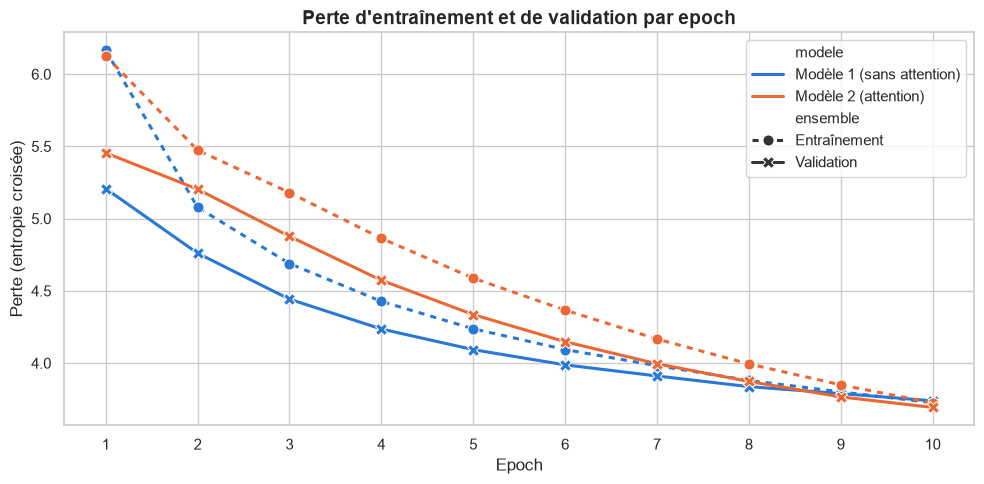

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
courbes = pd.concat([
    historique1.assign(modele="Modèle 1 (sans attention)"),
    historique2.assign(modele="Modèle 2 (attention)"),
]).melt(id_vars=["epoch", "modele"], value_vars=["perte_train", "perte_val"],
        var_name="ensemble", value_name="perte")
courbes["ensemble"] = courbes["ensemble"].map({"perte_train": "Entraînement", "perte_val": "Validation"})

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=courbes, x="epoch", y="perte", hue="modele", style="ensemble",
             markers=True, dashes={"Entraînement": (2, 2), "Validation": ""},
             palette=["#2a78d6", "#eb6834"], linewidth=2.2, markersize=8, ax=ax)
ax.set_title("Perte d'entraînement et de validation par epoch", fontsize=14, weight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("Perte (entropie croisée)")
ax.set_xticks(range(1, N_EPOCHS + 1))
ax.legend(title="")
plt.tight_layout()
plt.savefig("../reports/figures/courbes_modeles_1_2.png", dpi=150, bbox_inches="tight")
plt.show()